# 20 — The ANES 2016–2020–2024 panel: what the switchers believed before they switched

Part 8's ANES results (notebooks 14–15) measure attitudes in 2024, after the vote. The 2,171 ANES panelists were interviewed in 2016, 2020 and 2024, and were asked the same items each time, so the anti-elite, cultural and corporate items the CES lacks can be put *ahead* of the switch.

**Plan, fixed before any result was seen** (the harmonization is `src/data_collection/anes_panel_pull.py`):
- Sample: panelists with the 2016–2024 panel post-election weight `V240106b`; Biden 2020 voters **by their own 2020 post-election report** (`V202110x`), not 2024 recall.
- Groups: Biden→Harris (loyal), Biden→Trump (switchers), Biden→stayed home.
- Constructs, each the mean of 0–1 items (1 = the named direction): anti-politician (5 items), strong leader (1), anti-corporate (3), economic-left (5), immigration-conservative (5), cultural-conservative (5) — all asked in all three waves. 2020/2024 add rich-and-powerful, ANES immigration-crime, path to citizenship, transgender military service, diversity. Secondary, reported whatever they show: child-rearing authoritarianism (4) and racial resentment (4).
- Measures: switcher−loyal gap in pooled SD by wave, bootstrap 95% intervals; 2020→2024 change on identical-format items only; switching on 2020 (and 2016) attitudes; party affect; 2016 vote of the switchers by contemporaneous report; recall accuracy.

With 21 switchers (Kish effective n ≈ 11) every switcher figure is fragile: intervals are bootstrap (respondents resampled within group, weights carried), and weighted and unweighted gaps are both reported.

In [1]:
import numpy as np, pandas as pd, statsmodels.api as sm, matplotlib.pyplot as plt, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
RAW = Path('../data/raw/anes'); TABLES = Path('../outputs/tables'); FIGS = Path('../outputs/figures')
p = pd.read_csv(RAW / 'anes_panel_2016_2024.csv')
p = p[p.weight > 0].copy()
T3 = {  # items identical in wording in all three waves (formats differ in 2024 for trans_bathroom and gay_marriage)
    'anti_pol': ['big_interests', 'corrupt', 'trust_never', 'officials_dont_care', 'no_say'],
    'strong_leader': ['strong_leader'],
    'anti_corp': ['anti_bigbiz', 'millionaire_tax', 'spend_limits'],
    'econ_left': ['services', 'gov_insurance', 'guar_jobs', 'min_wage_raise', 'paid_leave'],
    'immig_cons': ['wall', 'dreamers_back', 'end_birthright', 'immig_decrease', 'immig_crime_cses'],
    'culture_cons': ['abortion', 'gay_marriage', 'gay_jobs_oppose', 'gay_adopt_no', 'trans_bathroom'],
    'authoritarian': ['auth_respect', 'auth_manners', 'auth_obedience', 'auth_behaved'],
    'racial_resent': ['rr_workway', 'rr_generations', 'rr_deserve', 'rr_tryhard'],
}
EXTRA2 = {'anti_corp': ['rich_powerful'], 'immig_cons': ['immig_crime', 'path_oppose'], 'culture_cons': ['trans_military_oppose', 'diversity_worse']}
for k, items in T3.items():
    for w in ('16', '20', '24'):
        p[f'{k}_{w}'] = p[[f'{i}_{w}' for i in items]].mean(axis=1)
    for w in ('20', '24'):
        p[f'{k}_full_{w}'] = p[[f'{i}_{w}' for i in items + EXTRA2.get(k, [])]].mean(axis=1)
p['grp'] = np.select([(p.vote20 == 'D') & (p.vote24 == 'D'), (p.vote20 == 'D') & (p.vote24 == 'R'), (p.vote20 == 'D') & (p.vote24 == 'NV'),
                      (p.vote20 == 'R') & (p.vote24 == 'R')], ['loyal', 'switch', 'stayhome', 'TT'], None)
b = p[p.grp.isin(['loyal', 'switch', 'stayhome'])].copy()
def wm(x, w):
    m = x.notna() & w.notna(); return np.average(x[m], weights=w[m]) if m.any() else np.nan
def W(s, m): return s.loc[m, 'weight'].sum() / s.weight.sum()
print(p.grp.value_counts())
sw = b[b.grp == 'switch'].weight
print('switcher Kish effective n: %.1f' % (sw.sum()**2 / (sw**2).sum()))

grp
loyal       856
TT          675
stayhome     64
switch       21
Name: count, dtype: int64
switcher Kish effective n: 10.7


## 1. Recall versus the record

In [2]:
m = p.dropna(subset=['vote20', 'recall20_in24'])
rc = pd.crosstab(m.vote20, m.recall20_in24); print('2020 vote reported in 2020 (rows) vs recalled in 2024 (cols):'); print(rc)
rs = p[(p.recall20_in24 == 'D') & (p.vote24 == 'R')]; cs = p[p.grp == 'switch']
print('\nrecall-defined Biden->Trump:', len(rs), ' reported 2020 vote:', rs.vote20.value_counts(dropna=False).to_dict())
print('true Biden->Trump:', len(cs), ' recalled 2020 vote:', cs.recall20_in24.value_counts(dropna=False).to_dict())
print('\nswitchers: 2016 vote reported in 2016 (rows) vs recalled in 2024 (cols)'); x = pd.crosstab(cs.vote16, cs.recall16_in24); print(x)
rc.to_csv(TABLES / 'anes_panel_recall_2020.csv'); x.to_csv(TABLES / 'anes_panel_recall_2016_switchers.csv')

2020 vote reported in 2020 (rows) vs recalled in 2024 (cols):
recall20_in24    D   NV   O    R
vote20                          
D              914   41   2   10
NV              27  185   2   36
O                9    9  10   10
R               21   37   5  703

recall-defined Biden->Trump: 26  reported 2020 vote: {'D': 14, 'R': 8, 'NV': 3, nan: 1}
true Biden->Trump: 21  recalled 2020 vote: {'D': 14, 'NV': 4, 'R': 3}

switchers: 2016 vote reported in 2016 (rows) vs recalled in 2024 (cols)
recall16_in24  D  NV  R
vote16                 
D              5   0  1
NV             1   2  0
O              1   0  1
R              1   3  6


## 2. Where the switchers came from in 2016, by the 2016 record

In [3]:
rows = []
for g in ['loyal', 'switch', 'stayhome']:
    s = b[(b.grp == g) & b.vote16.notna()]
    rows.append({'group': g, 'N': len(s), **{f'2016 {k}': W(s, s.vote16 == k) for k in ['D', 'R', 'NV', 'O']},
                 '2016 R unweighted': (s.vote16 == 'R').mean()})
t16 = pd.DataFrame(rows).set_index('group'); print(t16.round(3))
bb = b[b.grp != 'stayhome'].copy(); bb['y'] = (bb.grp == 'switch').astype(float)
rate = pd.DataFrame({k: {'N': (bb.vote16 == k).sum(), 'switchers': int(bb.loc[bb.vote16 == k, 'y'].sum()), 'share_of_coalition': W(bb, bb.vote16 == k),
                         'switch_rate': W(bb[bb.vote16 == k], bb.loc[bb.vote16 == k, 'y'] == 1)} for k in ['D', 'R', 'NV', 'O']}).T
print(rate.round(3))
rng = np.random.default_rng(1); s = cs[cs.vote16.notna()]; bs = []
for _ in range(4000):
    r = s.sample(len(s), replace=True, random_state=rng.integers(1e9)); bs.append(W(r, r.vote16 == 'R'))
ci = np.percentile(bs, [2.5, 97.5]); print('switchers who voted Trump 2016: %.2f weighted (95%% CI %.2f-%.2f)' % (W(s, s.vote16 == 'R'), *ci))
t16.assign(ci_lo_R=np.nan, ci_hi_R=np.nan).pipe(lambda d: d.assign(ci_lo_R=d.index.map({'switch': ci[0]}), ci_hi_R=d.index.map({'switch': ci[1]}))).to_csv(TABLES / 'anes_panel_2016_vote_by_group.csv')
rate.to_csv(TABLES / 'anes_panel_switch_by_2016_vote.csv')

            N  2016 D  2016 R  2016 NV  2016 O  2016 R unweighted
group                                                            
loyal     833   0.837   0.037    0.068   0.057              0.043
switch     21   0.584   0.321    0.085   0.010              0.476
stayhome   58   0.728   0.025    0.214   0.033              0.052
        N  switchers  share_of_coalition  switch_rate
D   694.0        6.0               0.783        0.030
R    46.0       10.0               0.047        0.274
NV   56.0        3.0               0.066        0.052
O    58.0        2.0               0.052        0.007
switchers who voted Trump 2016: 0.32 weighted (95% CI 0.13-0.61)


## 3. The gap, wave by wave

In [4]:
def gap(df, col, sd, a='switch', z='loyal', weighted=True):
    A, Z = df[df.grp == a], df[df.grp == z]
    if weighted: return (wm(A[col], A.weight) - wm(Z[col], Z.weight)) / sd
    return (A[col].mean() - Z[col].mean()) / sd
rng = np.random.default_rng(7); rows = []
for k in T3:
    for w in ('16', '20', '24'):
        col = f'{k}_{w}'; sd = p[col].std(); bs = []
        for _ in range(2000):
            r = b.groupby('grp', group_keys=False).apply(lambda s: s.sample(len(s), replace=True, random_state=rng.integers(1e9)))
            bs.append(gap(r, col, sd))
        lo, hi = np.percentile(bs, [2.5, 97.5])
        rows.append({'construct': k, 'wave': 2000 + int(w), 'gap': gap(b, col, sd), 'lo': lo, 'hi': hi, 'gap_unweighted': gap(b, col, sd, weighted=False),
                     'gap_stayhome': gap(b, col, sd, 'stayhome'),
                     **{f'mean_{g}': wm(p.loc[p.grp == g, col], p.loc[p.grp == g, 'weight']) for g in ['loyal', 'switch', 'stayhome', 'TT']}})
    for w in ('20', '24'):
        if k in EXTRA2:
            col = f'{k}_full_{w}'; sd = p[col].std()
            rows.append({'construct': k + '_full', 'wave': 2000 + int(w), 'gap': gap(b, col, sd), 'gap_unweighted': gap(b, col, sd, weighted=False), 'gap_stayhome': gap(b, col, sd, 'stayhome')})
gaps = pd.DataFrame(rows); gaps.to_csv(TABLES / 'anes_panel_gaps_by_wave.csv', index=False)
pd.set_option('display.width', 220); print(gaps.round(2).to_string(index=False))

        construct  wave   gap    lo    hi  gap_unweighted  gap_stayhome  mean_loyal  mean_switch  mean_stayhome  mean_TT
         anti_pol  2016 -0.23 -0.72  0.30            0.02          0.21        0.61         0.57           0.65     0.69
         anti_pol  2020 -0.01 -0.62  0.46            0.01          0.21        0.65         0.65           0.69     0.66
         anti_pol  2024  0.54  0.21  0.93            0.51          0.47        0.63         0.72           0.71     0.71
    strong_leader  2016  0.86  0.40  1.20            0.76          0.06        0.42         0.69           0.44     0.55
    strong_leader  2020  0.26 -0.37  0.88            0.19          0.33        0.30         0.38           0.40     0.57
    strong_leader  2024  0.46  0.01  0.91            0.74          0.38        0.24         0.39           0.36     0.58
        anti_corp  2016 -0.41 -0.76 -0.14           -0.58         -0.14        0.75         0.65           0.72     0.55
        anti_corp  2020 -0.64 -1

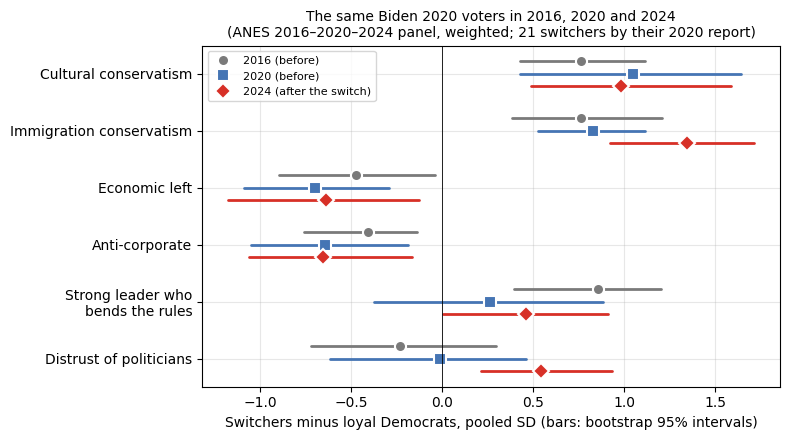

In [5]:
# Figure: switcher minus loyal Democrat, by wave (primary constructs)
order = ['culture_cons', 'immig_cons', 'econ_left', 'anti_corp', 'strong_leader', 'anti_pol']
labels = {'culture_cons': 'Cultural conservatism', 'immig_cons': 'Immigration conservatism', 'econ_left': 'Economic left',
          'anti_corp': 'Anti-corporate', 'strong_leader': 'Strong leader who\nbends the rules', 'anti_pol': 'Distrust of politicians'}
style = {2016: ('#7a7a7a', 'o'), 2020: ('#4575b4', 's'), 2024: ('#d73027', 'D')}
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, k in enumerate(order):
    for j, yr in enumerate([2016, 2020, 2024]):
        r = gaps[(gaps.construct == k) & (gaps.wave == yr)].iloc[0]; y = i + (j - 1) * 0.22; c, mk = style[yr]
        ax.plot([r.lo, r.hi], [y, y], color=c, lw=2, solid_capstyle='round')
        ax.plot(r.gap, y, marker=mk, ms=8, color=c, mec='white', mew=1.5, ls='none', label=str(yr) + (' (after the switch)' if yr == 2024 else ' (before)') if i == 0 else None)
ax.axvline(0, color='black', lw=0.6)
ax.set_yticks(range(len(order))); ax.set_yticklabels([labels[k] for k in order]); ax.invert_yaxis()
ax.set_xlabel('Switchers minus loyal Democrats, pooled SD (bars: bootstrap 95% intervals)')
ax.set_title('The same Biden 2020 voters in 2016, 2020 and 2024\n(ANES 2016–2020–2024 panel, weighted; 21 switchers by their 2020 report)', fontsize=10)
ax.legend(loc='upper left', fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIGS / 'anes_panel_gaps_by_wave.png', dpi=150, bbox_inches='tight'); plt.show()

## 4. Movement 2020→2024, identical items only

In [6]:
SAME = {'anti_pol': T3['anti_pol'], 'strong_leader': ['strong_leader'], 'anti_corp': T3['anti_corp'] + ['rich_powerful'], 'econ_left': T3['econ_left'],
        'immig_cons': T3['immig_cons'] + ['immig_crime', 'path_oppose'],
        'culture_cons': ['abortion', 'gay_jobs_oppose', 'gay_adopt_no', 'trans_military_oppose', 'diversity_worse'],  # bathroom and marriage changed format
        'authoritarian': T3['authoritarian'], 'racial_resent': T3['racial_resent']}
rng = np.random.default_rng(3); rows = []
for k, items in SAME.items():
    b[f'{k}_chg'] = b[[f'{i}_24' for i in items]].mean(axis=1) - b[[f'{i}_20' for i in items]].mean(axis=1)
    sd20 = p[[f'{i}_20' for i in items]].mean(axis=1).std(); c = f'{k}_chg'
    dd = lambda df: wm(df.loc[df.grp == 'switch', c], df.loc[df.grp == 'switch', 'weight']) - wm(df.loc[df.grp == 'loyal', c], df.loc[df.grp == 'loyal', 'weight'])
    bs = [dd(b.groupby('grp', group_keys=False).apply(lambda s: s.sample(len(s), replace=True, random_state=rng.integers(1e9)))) for _ in range(2000)]
    rows.append({'construct': k, **{f'change_{g}': wm(b.loc[b.grp == g, c], b.loc[b.grp == g, 'weight']) for g in ['loyal', 'switch', 'stayhome']},
                 'switch_minus_loyal_SD': dd(b) / sd20, 'lo_SD': np.percentile(bs, 2.5) / sd20, 'hi_SD': np.percentile(bs, 97.5) / sd20})
chg = pd.DataFrame(rows).set_index('construct'); print(chg.round(3)); chg.to_csv(TABLES / 'anes_panel_change_2020_2024.csv')
s = b[b.gay_marriage3_24.notna()]
print('\nsame-format marriage item (random half of 2024):', {g: (len(s[s.grp == g]), round(wm(s.loc[s.grp == g, 'gay_marriage_20'], s.loc[s.grp == g, 'weight']), 2),
      round(wm(s.loc[s.grp == g, 'gay_marriage3_24'], s.loc[s.grp == g, 'weight']), 2)) for g in ['loyal', 'switch']})

               change_loyal  change_switch  change_stayhome  switch_minus_loyal_SD  lo_SD  hi_SD
construct                                                                                       
anti_pol             -0.023          0.077            0.025                  0.573 -0.092  1.281
strong_leader        -0.058          0.012           -0.037                  0.219 -0.177  0.722
anti_corp             0.022         -0.002            0.025                 -0.106 -0.495  0.341
econ_left            -0.010          0.007           -0.064                  0.065 -0.692  0.694
immig_cons            0.076          0.177            0.134                  0.434  0.198  0.670
culture_cons          0.026          0.073            0.015                  0.196 -0.304  0.798
authoritarian         0.011         -0.048           -0.031                 -0.180 -0.494  0.180
racial_resent         0.046          0.127            0.086                  0.260 -0.069  0.719

same-format marriage item (ra

## 5. Does the 2020 (or 2016) attitude predict the 2024 switch?

In [7]:
def logit(df, cols):
    s = df.dropna(subset=cols); Z = (s[cols] - s[cols].mean()) / s[cols].std()
    return sm.GLM(s.y, sm.add_constant(Z), family=sm.families.Binomial(), freq_weights=s.weight / s.weight.mean()).fit(cov_type='HC1'), len(s), int(s.y.sum())
def boot(df, cols, n=1000, seed=5):
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        r = df.groupby('y', group_keys=False).apply(lambda s: s.sample(len(s), replace=True, random_state=rng.integers(1e9)))
        try: out.append(logit(r, cols)[0].params[cols].values)
        except Exception: pass
    return np.percentile(np.array(out), [2.5, 97.5], axis=0)
rows = []
for w in ('20', '16'):
    for k in T3:
        cols = [f'{k}_{w}']; r, n, e = logit(bb, cols); lo, hi = boot(bb, cols, 500)
        rows.append({'model': f'bivariate {w}', 'term': k, 'coef': r.params[cols[0]], 'boot_lo': lo[0], 'boot_hi': hi[0], 'hc1_p': r.pvalues[cols[0]], 'N': n, 'events': e})
for w in ('20', '24'):
    cols = [f'econ_left_{w}', f'immig_cons_{w}', f'culture_cons_{w}']; r, n, e = logit(bb, cols); lo, hi = boot(bb, cols)
    for j, c in enumerate(cols):
        rows.append({'model': f'joint {w}', 'term': c, 'coef': r.params[c], 'boot_lo': lo[j], 'boot_hi': hi[j], 'hc1_p': r.pvalues[c], 'N': n, 'events': e})
mods = pd.DataFrame(rows); print(mods.round(2).to_string(index=False)); mods.to_csv(TABLES / 'anes_panel_switch_models.csv', index=False)

       model            term  coef  boot_lo  boot_hi  hc1_p   N  events
bivariate 20        anti_pol -0.01    -0.64     0.62   0.93 877      21
bivariate 20   strong_leader  0.24    -0.61     0.75   0.10 875      21
bivariate 20       anti_corp -0.52    -0.85    -0.19   0.00 875      21
bivariate 20       econ_left -0.81    -1.31    -0.41   0.00 877      21
bivariate 20      immig_cons  0.85     0.55     1.41   0.00 877      21
bivariate 20    culture_cons  0.81     0.42     1.20   0.00 877      21
bivariate 20   authoritarian  0.55     0.12     0.98   0.00 874      21
bivariate 20   racial_resent  0.98     0.53     1.47   0.00 875      21
bivariate 16        anti_pol -0.21    -0.65     0.39   0.10 877      21
bivariate 16   strong_leader  0.90     0.40     1.51   0.00 876      21
bivariate 16       anti_corp -0.37    -0.64    -0.15   0.00 877      21
bivariate 16       econ_left -0.54    -1.00    -0.02   0.00 877      21
bivariate 16      immig_cons  0.85     0.48     1.36   0.00 877 

In [8]:
rows = []
for k in ['immig_cons', 'culture_cons', 'econ_left', 'anti_corp', 'anti_pol']:
    c = f'{k}_20'; s = bb.dropna(subset=[c]).copy(); s['t'] = pd.qcut(s[c].rank(method='first'), 3, labels=['low', 'mid', 'high'])
    for t, g in s.groupby('t'): rows.append({'index_2020': k, 'tercile': t, 'N': len(g), 'switchers': int(g.y.sum()), 'switch_rate': wm(g.y, g.weight)})
terc = pd.DataFrame(rows); print(terc.round(3).to_string(index=False)); terc.to_csv(TABLES / 'anes_panel_switch_by_tercile_2020.csv', index=False)
rows = []
for c in ['immig_cons_20', 'immig_cons_full_20', 'culture_cons_20', 'immig_cons_24']:
    s = bb.dropna(subset=[c]); hi = s[c] >= 0.5
    rows.append({'index': c, 'share_of_coalition': W(s, hi), 'switch_rate_hi': W(s[hi], s[hi].y == 1), 'switch_rate_lo': W(s[~hi], s[~hi].y == 1),
                 'switchers_hi': int(s[hi].y.sum()), 'share_of_switchers': W(s[s.y == 1], hi[s.y == 1])})
res = pd.DataFrame(rows); print(res.round(3).to_string(index=False)); res.to_csv(TABLES / 'anes_panel_reservoir.csv', index=False)

  index_2020 tercile   N  switchers  switch_rate
  immig_cons     low 293          0        0.000
  immig_cons     mid 292          4        0.017
  immig_cons    high 292         17        0.095
culture_cons     low 293          0        0.000
culture_cons     mid 292          7        0.029
culture_cons    high 292         14        0.082
   econ_left     low 293         15        0.088
   econ_left     mid 292          5        0.015
   econ_left    high 292          1        0.016
   anti_corp     low 292         13        0.084
   anti_corp     mid 291          4        0.017
   anti_corp    high 292          4        0.008
    anti_pol     low 293          7        0.042
    anti_pol     mid 292          6        0.028
    anti_pol    high 292          8        0.048
             index  share_of_coalition  switch_rate_hi  switch_rate_lo  switchers_hi  share_of_switchers
     immig_cons_20               0.072           0.195           0.028             8               0.355
immig_

## 6. Party affect and left-right placement, same people

In [9]:
rows = []
for v in ['therm_dem', 'therm_rep', 'pid7', 'lr_self', 'lr_dem', 'lr_rep']:
    for w in ('16', '20', '24'):
        rows.append({'var': v, 'wave': 2000 + int(w), **{g: wm(p.loc[p.grp == g, f'{v}_{w}'], p.loc[p.grp == g, 'weight']) for g in ['loyal', 'switch', 'stayhome', 'TT']}})
aff = pd.DataFrame(rows); print(aff.round(1).to_string(index=False)); aff.to_csv(TABLES / 'anes_panel_party_affect.csv', index=False)

      var  wave  loyal  switch  stayhome   TT
therm_dem  2016   68.6    66.3      69.7 27.0
therm_dem  2020   70.5    68.6      70.3 14.3
therm_dem  2024   73.4    36.3      61.8 13.4
therm_rep  2016   25.2    41.6      31.2 61.3
therm_rep  2020   17.1    39.1      27.6 75.8
therm_rep  2024   16.0    49.0      26.8 75.7
     pid7  2016    2.3     2.9       2.4  5.5
     pid7  2020    2.0     3.1       2.1  6.1
     pid7  2024    1.8     3.8       2.6  6.3
  lr_self  2016    4.5     6.9       5.9  7.0
  lr_self  2020    4.0     5.3       5.4  7.9
  lr_self  2024    3.6     5.4       5.1  7.7
   lr_dem  2016    4.0     5.7       4.9  2.2
   lr_dem  2020    4.0     5.1       5.1  1.4
   lr_dem  2024    3.6     5.0       4.1  1.4
   lr_rep  2016    7.0     5.2       5.2  7.5
   lr_rep  2020    7.1     5.0       5.7  8.1
   lr_rep  2024    7.6     6.7       6.4  8.1


## 7. Does recall distort the 2024 profile?

In [10]:
p['grp_recall'] = np.select([(p.recall20_in24 == 'D') & (p.vote24 == 'D'), (p.recall20_in24 == 'D') & (p.vote24 == 'R')], ['loyal', 'switch'], None)
rows = []
for k in ['anti_pol', 'strong_leader', 'anti_corp', 'econ_left', 'immig_cons', 'culture_cons']:
    c = f'{k}_24'; sd = p[c].std()
    g = lambda gc: (wm(p.loc[p[gc] == 'switch', c], p.loc[p[gc] == 'switch', 'weight']) - wm(p.loc[p[gc] == 'loyal', c], p.loc[p[gc] == 'loyal', 'weight'])) / sd
    mis = p[(p.grp_recall == 'switch') & (p.grp != 'switch')]
    rows.append({'construct': k, 'gap_true': g('grp'), 'gap_recall': g('grp_recall'), 'misclassified_mean': wm(mis[c], mis.weight),
                 'true_switch_mean': wm(p.loc[p.grp == 'switch', c], p.loc[p.grp == 'switch', 'weight']), 'TT_mean': wm(p.loc[p.grp == 'TT', c], p.loc[p.grp == 'TT', 'weight'])})
rv = pd.DataFrame(rows).set_index('construct'); print(rv.round(2)); rv.to_csv(TABLES / 'anes_panel_recall_vs_true_profile.csv')
print('misclassified N:', len(p[(p.grp_recall == 'switch') & (p.grp != 'switch')]), ' Democratic thermometer 2024:', round(wm(mis.therm_dem_24, mis.weight), 1))

               gap_true  gap_recall  misclassified_mean  true_switch_mean  TT_mean
construct                                                                         
anti_pol           0.54        0.57                0.74              0.72     0.71
strong_leader      0.46        0.52                0.43              0.39     0.58
anti_corp         -0.65       -0.62                0.58              0.58     0.50
econ_left         -0.64       -0.66                0.52              0.59     0.41
immig_cons         1.34        1.19                0.58              0.64     0.70
culture_cons       0.98        0.91                0.49              0.43     0.53
misclassified N: 12  Democratic thermometer 2024: 46.9


## Reading

See technical appendix I.9 for the numbers and main report Part 8, "Before the switch". Short version: the cultural gap was at full size in 2020 and three-quarters of it in 2016; the immigration gap was about 60% there and grew; the switchers were less economically left and less anti-corporate than loyal Democrats before as after; distrust of politicians appeared only in 2024; the strong-leader item moved with the times. The switchers liked the Democratic Party as much as loyal Democrats in 2016 and 2020. Everything rests on 21 people.